# Crystallization: yield from solubility and the MSMPR size distribution

`difflow.units.crystallizer` has the solubility / yield library (cooling, evaporative, hydrates), the MSMPR
population balance with power-law kinetics, and the `Crystallizer` palette unit.

**Every curve and kinetic constant below is SYNTHETIC (illustrative).** The sucrose, Na$_2$SO$_4$ and Na$_2$CO$_3$
solubility data and the published worked examples (Geankoplis Sec. 12.11, McCabe Ch. 27, Wankat Ch. 17) are not
reproduced: their numbers could not be recalled with confidence, so the notebook checks the closed forms against
independent numerical oracles instead.

In [1]:
import math
import jax, jax.numpy as jnp, numpy as np
import matplotlib.pyplot as plt
from scipy import integrate
jax.config.update("jax_enable_x64", True)
from difflow import (Solubility, crystal_balance, crystal_yield, supersaturation, Crystallizer, CrystallizerParams,
                     make_stream, msmpr_distribution, msmpr_moments, msmpr_dominant_size, msmpr_mass_median_size,
                     fit_msmpr, msmpr_steady_state)
K0 = 273.15

## 1. Cooling yield of an anhydrous solute (a sugar-like syrup, synthetic curve)

Solubility in kg solute per kg water, $c_{sat} = 0.60 + 0.006\,(T - 273.15)$ (synthetic). Feed: 0.95 kg solute per kg
water at 70 C, cooled to 20 C. The yield is $C = (S_0 - c_{sat}W)/(1 - c_{sat}\cdot 0)$ with no hydrate.

In [2]:
syrup = Solubility.polynomial([0.60, 0.006], hydrate_waters=0, solute_MW=342.3)
S0, W0 = 0.95, 1.0
for Tc in (60.0, 40.0, 20.0, 0.0):
    b = crystal_balance(S0, W0, K0 + Tc, syrup)
    print(f"T = {Tc:4.0f} C  c_sat = {float(b['c_sat']):.3f}  crystals = {float(b['crystals']):.4f} kg/kg water"
          f"  yield = {100 * float(b['yield_fraction']):5.1f} %   S = {float(supersaturation(S0 / W0, K0 + Tc, syrup)):.3f}")
b = crystal_balance(S0, W0, K0 + 20.0, syrup)
print("balance closure:", float(S0 - b['crystal_solute'] - b['liquor_solute']), float(W0 - b['crystal_water'] - b['liquor_water']))

T =   60 C  c_sat = 0.960  crystals = 0.0000 kg/kg water  yield =   0.0 %   S = 0.990
T =   40 C  c_sat = 0.840  crystals = 0.1100 kg/kg water  yield =  11.6 %   S = 1.131
T =   20 C  c_sat = 0.720  crystals = 0.2300 kg/kg water  yield =  24.2 %   S = 1.319
T =    0 C  c_sat = 0.600  crystals = 0.3500 kg/kg water  yield =  36.8 %   S = 1.583
balance closure: 0.0 0.0


## 2. A hydrate, and a smooth switch between two solid forms

With $\nu$ waters of crystallization the crystal takes water out of the liquor, so the same cooling gives more
solid *and* a more concentrated liquor. A second solid form above a transition temperature is a logistic blend in $T$
(width 0.5 K here), differentiable through the switch.

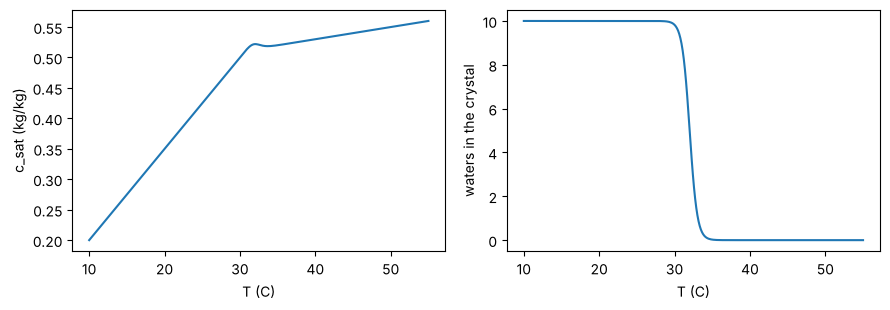

yield and d(yield)/dT across the transition: [(25, 0.8615, -0.0383), (31.5, 0.298, -0.2512), (32, 0.1906, -0.1694), (32.5, 0.1288, -0.0833), (40, 0.07, -0.002)]


In [3]:
upper = Solubility.polynomial([0.45, 0.002], hydrate_waters=0.0, solute_MW=142.0)      # anhydrous form (synthetic)
two_form = Solubility.polynomial([0.05, 0.015], hydrate_waters=10.0, solute_MW=142.0,    # decahydrate-like (synthetic)
                                 upper=upper, T_transition=K0 + 32.0, width=0.5)
Ts = np.linspace(K0 + 10, K0 + 55, 300)
cs = np.asarray(two_form.c_sat(Ts)); nu = np.asarray(two_form.hydration(Ts))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(Ts - K0, cs); ax[0].set_xlabel("T (C)"); ax[0].set_ylabel("c_sat (kg/kg)")
ax[1].plot(Ts - K0, nu); ax[1].set_xlabel("T (C)"); ax[1].set_ylabel("waters in the crystal")
plt.tight_layout(); plt.show()
g = jax.grad(lambda T: crystal_yield(0.6, 1.0, T, two_form))
print("yield and d(yield)/dT across the transition:",
      [(Tc, round(float(crystal_yield(0.6, 1.0, K0 + Tc, two_form)), 4), round(float(g(K0 + Tc)), 4)) for Tc in (25, 31.5, 32, 32.5, 40)])

## 3. MSMPR: moments, dominant size, the "ln n vs L" fit

$n(L) = n_0 e^{-L/G\tau}$, $m_k = k!\,n_0 (G\tau)^{k+1}$, $L_D = 3G\tau$, $L_{50} = 3.672\,G\tau$ (the root of the gamma(4)
cumulative mass fraction, computed). Check against quadrature and the argmax.

In [4]:
n0, G, tau = 3.0e9, 2.0e-8, 1800.0
Gt = G * tau
mom = np.asarray(msmpr_moments(n0, G, tau))
quad = [integrate.quad(lambda L, k=k: L**k * float(msmpr_distribution(L, n0, G, tau)), 0, 60 * Gt, epsabs=0, epsrel=1e-12)[0] for k in range(4)]
print("moments / quadrature - 1:", mom / np.array(quad) - 1)
L = np.linspace(0, 10 * Gt, 20001)
print("argmax of L^3 n:", L[np.argmax(L**3 * np.asarray(msmpr_distribution(L, n0, G, tau)))], " 3 G tau:", float(msmpr_dominant_size(G, tau)))
print("L50 / (G tau) =", float(msmpr_mass_median_size(G, tau)) / Gt)
rng = np.random.default_rng(1)
Lm = np.linspace(1e-5, 6 * Gt, 30)
nm = np.asarray(msmpr_distribution(Lm, n0, G, tau)) * np.exp(rng.normal(0, 0.03, Lm.size))
Gt_fit, n0_fit = fit_msmpr(Lm, nm)
print(f"fit from noisy data: G tau = {float(Gt_fit):.3e} (true {Gt:.3e}), n0 = {float(n0_fit):.3e} (true {n0:.3e})")

moments / quadrature - 1: [-1.11022302e-16  2.22044605e-16 -9.99200722e-16  6.66133815e-16]
argmax of L^3 n: 0.00010800000000000001  3 G tau: 0.00010800000000000001
L50 / (G tau) = 3.6720607488508956


fit from noisy data: G tau = 3.586e-05 (true 3.600e-05), n0 = 3.031e+09 (true 3.000e+09)


## 4. Residence time versus median size, by gradient

With power-law kinetics $G = k_g\Delta C^g$, $B_0 = k_b M_T^j \Delta C^b$ the supersaturation $\Delta C$ is the root of the
solute balance closed with the third moment, so $G$ itself depends on $\tau$ and $L_{50}(\tau) \neq 3.672\,G\tau$ at a
fixed $G$. The gradient comes from the implicit-function derivative of that root.

tau =    200 s  dC = 2.113e-01  L50 =   142.7 um  dL50/dtau = 0.6576 um/s
tau =    400 s  dC = 1.716e-01  L50 =   208.8 um  dL50/dtau = 0.1411 um/s
tau =    800 s  dC = 1.182e-01  L50 =   238.7 um  dL50/dtau = 0.0438 um/s
tau =   1600 s  dC = 7.894e-02  L50 =   260.6 um  dL50/dtau = 0.0183 um/s
tau =   3200 s  dC = 5.217e-02  L50 =   280.1 um  dL50/dtau = 0.0085 um/s
tau =   6400 s  dC = 3.430e-02  L50 =   298.6 um  dL50/dtau = 0.0042 um/s


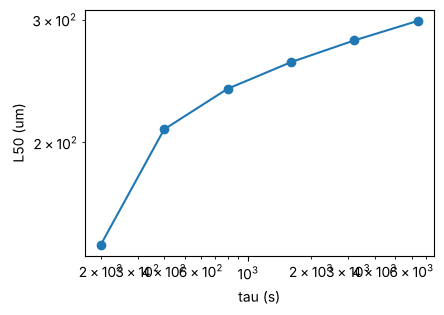

gradient vs finite difference at tau = 800 s: 0.0438133589425061 0.04381338731942531


k_g -> infinity approaches the equilibrium yield: ['4.4e-02', '5.1e-03', '6.0e-04', '2.5e-05', '1.0e-06', '1.7e-09']


In [5]:
sol = Solubility.polynomial([0.35, 0.0075], hydrate_waters=10, solute_MW=142.0)      # synthetic
kin = (2.0e-6, 1.5, 1.0e9, 2.0, 0.6)                                                  # synthetic k_g, g, k_b, b, j
def run(t, kin=kin):
    return msmpr_steady_state(0.60, 1.0, K0 + 5.0, sol, kin, t, crystal_density=1460.0, liquor_density=1250.0)
taus = np.array([200.0, 400.0, 800.0, 1600.0, 3200.0, 6400.0])
L50 = np.array([float(run(t)["L_50"]) for t in taus]) * 1e6
dL = np.array([float(jax.grad(lambda t: run(t)["L_50"] * 1e6)(t)) for t in taus])
dC = np.array([float(run(t)["delta_C"]) for t in taus])
for t, l, d, c in zip(taus, L50, dL, dC):
    print(f"tau = {t:6.0f} s  dC = {c:.3e}  L50 = {l:7.1f} um  dL50/dtau = {d:.4f} um/s")
fig, ax = plt.subplots(figsize=(4.5, 3.2)); ax.loglog(taus, L50, "o-"); ax.set_xlabel("tau (s)"); ax.set_ylabel("L50 (um)"); plt.show()
h = 1e-3 * 800.0
print("gradient vs finite difference at tau = 800 s:", dL[2], (float(run(800 + h)["L_50"]) - float(run(800 - h)["L_50"])) * 1e6 / (2 * h))
eq = float(crystal_yield(0.60, 1.0, K0 + 5.0, sol))
print("k_g -> infinity approaches the equilibrium yield:",
      [f"{abs(float(run(900.0, (kg,) + kin[1:])['crystals']) - eq) / eq:.1e}" for kg in (1e-4, 1e-2, 1.0, 1e3, 1e6, 1e12)])

## 5. The unit in a flowsheet

An `Evaporator` concentrate goes into a cooling `Crystallizer`; the mother liquor recycles to the evaporator.

In [6]:
from difflow import Evaporator, EvaporatorParams, Mixer
from difflow.flowsheet import Flowsheet, Unit
evap = Evaporator(EvaporatorParams(solute_species=["Na2SO4"], solute_MW=[142.0], solvent="water", x_product=0.30,
                                   bpr_model="ideal", vant_hoff_i=3.0, P_vapor_space=60e3, steam_P=300e3, U=1500.0))
xtal = Crystallizer(CrystallizerParams(solute="Na2SO4", solute_MW=142.0, solvent="water", T=278.15,
                                       solubility_coeffs=[0.35, 0.0075], hydrate_waters=10.0))
fresh = make_stream({"Na2SO4": 0.30 * 1000 / 142.0, "water": 1.7 * 1000 / 18.015}, T=313.15, P=1e5)
fs = Flowsheet(species_order=["water", "Na2SO4"])
fs.add_feed("feed", fresh)
fs.add_unit(Unit("mix", Mixer(["water", "Na2SO4"]), ["feed", "recycle"], ["evap_in"]))
fs.add_unit(Unit("evap", evap, ["evap_in"], ["conc", "vap"]))
fs.add_unit(Unit("xtal", xtal, ["conc"], ["crystals", "liquor"]))
fs.add_recycle("liquor", "recycle")
guess = {"recycle": make_stream({"Na2SO4": 0.5, "water": 40.0}, T=278.15, P=1e5)}
out = fs.solve(tear_initial=guess, tol=1e-12, max_iter=400, on_nonconvergence="raise")
print("crystals / fresh solute:", float(out["crystals"]["F_Na2SO4"] / fresh["F_Na2SO4"]))
print("bound water per solute :", float(out["crystals"]["F_water"] / out["crystals"]["F_Na2SO4"]))

crystals / fresh solute: 0.9999999999999948
bound water per solute : 10.0
